In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu trực tiếp từ UCI (có thể mất vài giây)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"
df = pd.read_excel(url)

# Lấy mẫu 10% để giảm tải (random_state để tái lập kết quả)
df_sample = df.sample(frac=0.1, random_state=42).copy()

print(f"Kích thước ban đầu: {df.shape}")
print(f"Kích thước mẫu 10%: {df_sample.shape}")

Kích thước ban đầu: (541909, 8)
Kích thước mẫu 10%: (54191, 8)


In [2]:
# 1. Xóa các dòng có giá trị null ở các cột quan trọng
df_clean = df_sample.dropna(subset=['CustomerID', 'Description', 'InvoiceDate'])

# 2. Chuyển InvoiceDate sang datetime
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# 3. Lọc bỏ Returns (Quantity <= 0 hoặc InvoiceNo bắt đầu bằng 'C')
# Lưu ý: Cần chuyển InvoiceNo sang string để kiểm tra ký tự 'C'
df_clean = df_clean[df_clean['Quantity'] > 0]
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]

# 4. Lọc bỏ Free items (UnitPrice <= 0)
df_clean = df_clean[df_clean['UnitPrice'] > 0]

# 5. (Tùy chọn) Xóa các dòng trùng lặp nếu có
df_clean = df_clean.drop_duplicates()

print(f"Số dòng sau khi làm sạch: {len(df_clean)}")
print(df_clean.dtypes) # Kiểm tra kiểu dữ liệu

Số dòng sau khi làm sạch: 39573
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


/tmp/ipykernel_1192/3056423137.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])


In [3]:
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['UnitPrice']

# Kiểm tra nhanh 5 dòng đầu
print(df_clean[['Country', 'Quantity', 'UnitPrice', 'Revenue']].head())

               Country  Quantity  UnitPrice  Revenue
209268  United Kingdom        24       0.85    20.40
207108  United Kingdom         4       6.95    27.80
167085  United Kingdom         4       0.65     2.60
471836  United Kingdom         3       1.95     5.85
115865  United Kingdom         2       9.95    19.90


/tmp/ipykernel_1192/1354289637.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_countries.index, y=top_10_countries.values, palette='viridis')


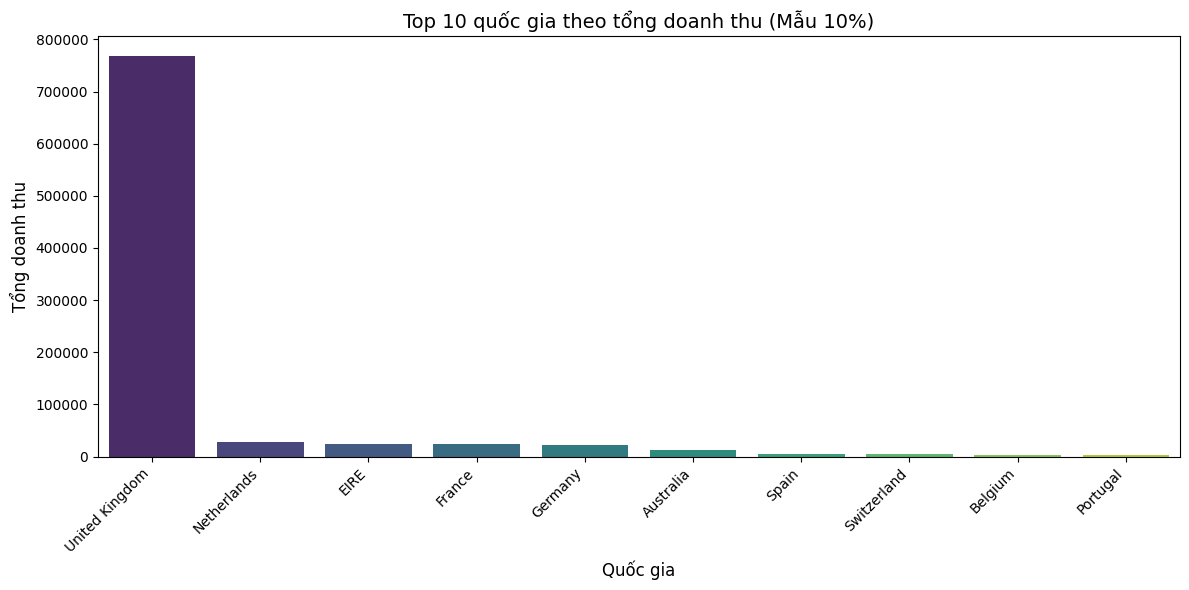

In [4]:
# Tính tổng doanh thu theo quốc gia
country_revenue = df_clean.groupby('Country')['Revenue'].sum().sort_values(ascending=False)

# Lấy top 10
top_10_countries = country_revenue.head(10)

# Vẽ biểu đồ
plt.figure(figsize=(12, 6))
# Sử dụng Seaborn để biểu đồ đẹp hơn, hoặc dùng trực tiếp top_10_countries.plot(kind='bar')
sns.barplot(x=top_10_countries.index, y=top_10_countries.values, palette='viridis')

plt.title('Top 10 quốc gia theo tổng doanh thu (Mẫu 10%)', fontsize=14)
plt.xlabel('Quốc gia', fontsize=12)
plt.ylabel('Tổng doanh thu', fontsize=12)
plt.xticks(rotation=45, ha='right') # Xoay nhãn để không bị đè
plt.tight_layout()
plt.show()